# 39 - System II: Careful Identifiability Re-check + SBC Repair Recombination

Follow-up to `notebooks/35-38` (System II matched-protocol SBC calibration failure) and to
`docs/Manuscript/system_ii_sbc_repair_directions.md`.

**This notebook has two independent parts:**

**Part I - identifiability re-check for `xi_reb`/`z_A0_eff`.** `nb35`/`nb37`/`nb38`
repeatedly flag these two parameters as the worst SBC offenders, which invites the
hypothesis "maybe they're just not identifiable under S-B". **That hypothesis must clear a
high bar before being reported**, because this project has already been burned twice by
premature identifiability claims that a deeper look overturned:

- The original `(alpha, eta_col)` "banana" (`nb26`) looked like a genuine degeneracy under a
  single-channel (F_R-only) view, but combining it with an already-available channel
  (`T_reb`) collapsed it (`nb29b` Section 1). **Full retraction**, not a numbers correction
  -- see `finding_sa_headline_retracted`.
- The replacement `(alpha, beta_r)` banana (`nb29b` Sections 1-2) survived combination of
  the full summary-statistic feature set and was reported as the article's real headline
  (`finding_alpha_beta_r_banana`) -- but `nb29b` Sections 3-4 later showed *that* also
  turned out to be a **representation artifact**: the noise-calibrated FIM off-diagonal
  collapses from ~0.6-0.85 to ~0.00 once the raw, unaggregated transient is used instead of
  the 66-D whole-window summary statistics. Modestly finer time resolution (a 108-D
  sub-window statistic) did **not** help -- only the fully unaggregated signal did.

The lesson this notebook must respect: **a grid-scan ridge or a summary-statistic FIM
off-diagonal is evidence about the *feature representation*, not automatically about the
*plant physics*.** Any identifiability claim here has to be checked against (a) multiple
feature-channel subsets, not just one, and (b) a richer/raw-trajectory representation of the
same physical channels, before it is reported as a genuine limit rather than an artifact of
`compute_summaries`'s hand-crafted 66-D aggregation. Both `xi_reb` (scales `Q_reb` directly)
and `z_A0_eff` (feeds into the reactor composition balance that drives `T_r`, `x_D`, `x_B`)
have clear, direct physical pathways into several S-B channels -- there is no obvious a
priori reason to expect either is unidentifiable, so the FIM/grid-scan evidence has to
actually earn that conclusion.

**Part II - SBC repair recombination.** `nb38` found two *separate* partial improvements
over the matched-protocol baseline (min-KS `p=2.21e-3`): a fixed-nominal warm start
(`p=2.54e-2`) and logit-parameter-space training (`p=7.03e-2`, but only 1/3 seeds). Neither
was tried together, and the logit-space experiment used an approximate empirical-Gaussian
surrogate for the induced prior rather than the exact pushforward density. This part (a)
recombines the two fixes and (b) replaces the surrogate prior with the analytically exact
induced density, then compares four arms head-to-head at the same reduced SBC budget nb38
used (`N_SBC=120`, `N_POST=120`, 3 seeds).

Run Part I and Part II independently -- Part II does not depend on Part I's outcome (both
are worth doing regardless of what Part I finds). Do not promote any posterior from this
notebook without the `N_SBC>=400`, 5+-seed confirmation step described in
`system_ii_sbc_repair_directions.md` Section 3e.


In [1]:
import json, pathlib, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import jax.numpy as jnp
from scipy import stats as scipy_stats

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from sbi.inference import SNPE
from sbi.neural_nets import posterior_nn
from cstr_sbi.recycle.physics import (
    PARAM_NAMES, NOMINAL_CTRL_SB, NOMINAL_INLET, NOMINAL_THETA,
    simulate_trajectory_explicit_jit, extract_observations_explicit,
)
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D
from cstr_sbi.recycle.simulator import nominal_warm_start
from cstr_sbi.recycle.summaries import compute_summaries, summary_names, RAW_INDEX, SB_CHANNELS
from sbi_pipeline import _structure_config, _simulate_summary
import identifiability_scan as idscan
from fim_utils import compute_fim, offdiag_ratio, cov_offdiag_corr, crb_report

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SBI_LOGS = ROOT / 'sbi-logs'
FIGURES = ROOT / 'figures'
for path in [DATA, RESULTS, SBI_LOGS, FIGURES]:
    path.mkdir(exist_ok=True)

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
ARCH = 'zuko_nsf'
HIDDEN = 60
TRANSFORMS = 3
MAX_EPOCHS = 120
STOP_AFTER_EPOCHS = 12
N_POST = 120

LOG_SIGMA = np.array([0.16, 0.16, 0.10, 0.16, 0.055], dtype=np.float32)
MATCHED_LOGN_BANK_5K = DATA / 'wu2003_sbi_train_sb_lognormal_true_n5000.npz'
MATCHED_LOGN_SBC_SET = RESULTS / '37_sysII_lognormal_sbc_set_n120.npz'
FIXEDY0_BANK_N3000 = DATA / 'wu2003_sbi_train_sb_lognormal_fixed_y0_n3000.npz'
FIXEDY0_SBC_SET_N120 = RESULTS / '38_sysII_lognormal_fixed_y0_sbc_set_n120.npz'
assert MATCHED_LOGN_BANK_5K.exists(), MATCHED_LOGN_BANK_5K
assert MATCHED_LOGN_SBC_SET.exists(), MATCHED_LOGN_SBC_SET
assert FIXEDY0_BANK_N3000.exists(), FIXEDY0_BANK_N3000
assert FIXEDY0_SBC_SET_N120.exists(), FIXEDY0_SBC_SET_N120

print(f'ROOT={ROOT}')
print(f'Parameters: {PARAM_NAMES}')
print('NOMINAL_THETA:', np.asarray(NOMINAL_THETA))


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT=/Users/simo/inso-po-RD/cstr-model-optimisation/research_project
Parameters: ['alpha', 'beta_r', 'eta_col', 'xi_reb', 'z_A0_eff']
NOMINAL_THETA: [1.  1.  1.  1.  0.9]


---
# Part I - Identifiability re-check: `xi_reb`, `z_A0_eff`

## Section 1 - Full 5x5 FIM at two operating points

Exactly the article-established methodology (`fim_utils.compute_fim`, `J^T Sigma^-1 J`,
Jacobian via central finite differences, `Sigma` from real 0.3%-sensor-noise replicate
variance) -- the same one that produced the article's headline `+0.901` `(alpha, beta_r)`
off-diagonal at nominal and that later resolved it as a representation artifact
(`nb29b` Section 4). Reusing this methodology unchanged (rather than inventing a new one) is
deliberate: it is the only identifiability tool on this project that has already been
cross-checked against a richer representation and shown to give the *correct* answer once
that check is done.

Computed at two points: nominal (`theta=[1,1,1,1,0.90]`, the lognormal prior's median) and a
combined reboiler-starvation / feed-composition-fault point away from nominal
(`xi_reb=0.70, z_A0_eff=0.80`, chosen to sit well inside the prior support while probing a
region the SBC failures are drawn from, in the same spirit `nb29b` used the W11 combined-fault
point rather than only nominal).

**Methodological correction (2026-09-01).** The original version of this notebook (and
`nb40`) reported `offdiag_ratio`'s raw, normalised *information*-matrix entry as if it were a
posterior *correlation*. For a multi-parameter FIM these can have **opposite signs** once the
other parameters are accounted for -- confirmed numerically in `nb40` (raw off-diagonal
`+0.40` vs. the correctly inverted-covariance correlation `-0.60` at one point, and the
reverse sign at another; see `scripts/fim_utils.py::cov_offdiag_corr`, added to fix this).
Every FIM-based correlation number in this notebook has been recomputed below using
`cov_offdiag_corr` (the Laplace/Gaussian-approximation correlation from the *inverted* FIM,
which is the quantity actually comparable to a trained posterior's empirical sample
correlation). The raw `offdiag_ratio` value is still printed alongside it, for transparency
and because it remains valid for one narrower purpose: checking whether a representation
collapses a coupling towards exactly zero (as in `nb29b`'s `(alpha, eta_col)` retraction) --
just not for reading off sign or magnitude against a posterior.

In [2]:
EPS_FIM = np.array([0.02, 0.02, 0.02, 0.02, 0.01])
Y0_FIM = np.asarray(nominal_warm_start('S-B'))
THETA_NOM_FIM = np.asarray(NOMINAL_THETA, dtype=np.float64).copy()
THETA_DEGRADED_FIM = np.array([1.0, 1.0, 1.0, 0.70, 0.80], dtype=np.float64)


def sim_raw_full(theta_np, seed=None, noise_pct=NOISE_PCT):
    th = jnp.array(theta_np, dtype=jnp.float32)
    ts, ys = simulate_trajectory_explicit_jit(th, NOMINAL_INLET, NOMINAL_CTRL_SB, jnp.array(Y0_FIM),
                                               t_final=2.0, n_save=120, rtol=1e-3, atol=1e-5)
    raw = np.asarray(extract_observations_explicit(ys, th, NOMINAL_CTRL_SB))
    t_h = np.asarray(ts)
    if seed is not None:
        rng = np.random.default_rng(seed)
        scale = np.maximum(np.max(np.abs(raw), axis=0), 1e-6)
        raw = raw + rng.normal(0, noise_pct * scale, raw.shape)
    return raw, t_h


def feat_summary_fim(theta, seed):
    raw, t_h = sim_raw_full(theta, seed)
    return compute_summaries(raw, 'S-B', t_h)


names_sb = summary_names('S-B')
FIM_nom = compute_fim(feat_summary_fim, THETA_NOM_FIM, EPS_FIM, seed_offset=0)
FIM_deg = compute_fim(feat_summary_fim, THETA_DEGRADED_FIM, EPS_FIM, seed_offset=0)
print('FIM computed at both points (compute_summaries, 66-D, real 0.3% noise).')


FIM computed at both points (compute_summaries, 66-D, real 0.3% noise).


In [3]:
def report_fim(FIM, theta_point, label):
    D = np.sqrt(np.clip(np.diag(FIM), 1e-30, None))
    info_offdiag = FIM / np.outer(D, D)
    n = FIM.shape[0]
    cov_corr = np.array([[cov_offdiag_corr(FIM, i, j) for j in range(n)] for i in range(n)])
    crb = crb_report(FIM, names=PARAM_NAMES)
    print(f'=== {label} (theta={np.round(theta_point, 3).tolist()}) ===')
    print('Inverted-covariance correlation matrix (the quantity comparable to a posterior'
          ' -- use this one):')
    print(pd.DataFrame(cov_corr, index=PARAM_NAMES, columns=PARAM_NAMES).round(3))
    print('\nFor reference only -- raw normalised information-matrix off-diagonal (NOT a'
          ' correlation, can have the opposite sign, see correction note above):')
    print(pd.DataFrame(info_offdiag, index=PARAM_NAMES, columns=PARAM_NAMES).round(3))
    print(f"cond(FIM) = {crb['cond']:.2e}")
    print('Cramer-Rao sd by parameter:', {k: round(v, 4) for k, v in crb['sd_by_name'].items()})
    print()
    return cov_corr, info_offdiag, crb

corr_nom, info_offdiag_nom, crb_nom = report_fim(FIM_nom, THETA_NOM_FIM, 'Nominal')
corr_deg, info_offdiag_deg, crb_deg = report_fim(FIM_deg, THETA_DEGRADED_FIM, 'Combined xi_reb/z_A0_eff fault point')


=== Nominal (theta=[1.0, 1.0, 1.0, 1.0, 0.9]) ===
Inverted-covariance correlation matrix (the quantity comparable to a posterior -- use this one):
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.275   -0.658   0.218    -0.478
beta_r    0.275   1.000   -0.115   0.246    -0.120
eta_col  -0.658  -0.115    1.000  -0.052     0.761
xi_reb    0.218   0.246   -0.052   1.000    -0.201
z_A0_eff -0.478  -0.120    0.761  -0.201     1.000

For reference only -- raw normalised information-matrix off-diagonal (NOT a correlation, can have the opposite sign, see correction note above):
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000  -0.221    0.551  -0.214    -0.116
beta_r   -0.221   1.000   -0.060  -0.179     0.015
eta_col   0.551  -0.060    1.000  -0.258    -0.699
xi_reb   -0.214  -0.179   -0.258   1.000     0.262
z_A0_eff -0.116   0.015   -0.699   0.262     1.000
cond(FIM) = 6.25e+02
Cramer-Rao sd by parameter: {'alpha': np.float64(0.0003), 'beta_r': np.flo

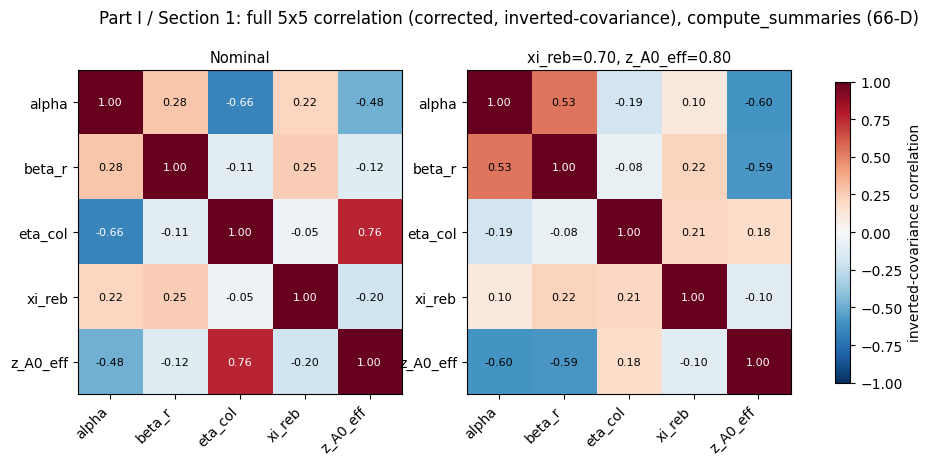

Worst-correlated pairs (|corr| ranked, corrected inverted-covariance metric), nominal:
  (eta_col, z_A0_eff): nominal=+0.761  degraded_pt=+0.182   [raw info off-diag, for reference: nominal=-0.699  degraded_pt=-0.105]
  (alpha, eta_col): nominal=-0.658  degraded_pt=-0.189   [raw info off-diag, for reference: nominal=+0.551  degraded_pt=+0.120]
  (alpha, z_A0_eff): nominal=-0.478  degraded_pt=-0.596   [raw info off-diag, for reference: nominal=-0.116  degraded_pt=+0.395]
  (alpha, beta_r): nominal=+0.275  degraded_pt=+0.533   [raw info off-diag, for reference: nominal=-0.221  degraded_pt=-0.280]
  (beta_r, xi_reb): nominal=+0.246  degraded_pt=+0.220   [raw info off-diag, for reference: nominal=-0.179  degraded_pt=-0.181]
  (alpha, xi_reb): nominal=+0.218  degraded_pt=+0.102   [raw info off-diag, for reference: nominal=-0.214  degraded_pt=-0.022]
  (xi_reb, z_A0_eff): nominal=-0.201  degraded_pt=-0.102   [raw info off-diag, for reference: nominal=+0.262  degraded_pt=-0.003]
  (beta_r, z_

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, corr, title in [(axes[0], corr_nom, 'Nominal'), (axes[1], corr_deg, 'xi_reb=0.70, z_A0_eff=0.80')]:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(5)); ax.set_xticklabels(PARAM_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(5)); ax.set_yticklabels(PARAM_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(corr[i, j]) > 0.6 else 'black')
    ax.set_title(title, fontsize=10.5)
fig.colorbar(im, ax=axes, shrink=0.85, label='inverted-covariance correlation')
fig.suptitle('Part I / Section 1: full 5x5 correlation (corrected, inverted-covariance), compute_summaries (66-D)', fontsize=12)
fig.savefig(FIGURES / '39_sysII_fim_correlation_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

print('Worst-correlated pairs (|corr| ranked, corrected inverted-covariance metric), nominal:')
pairs = [(i, j) for i in range(5) for j in range(i+1, 5)]
ranked = sorted(pairs, key=lambda p: -abs(corr_nom[p]))
for i, j in ranked:
    print(f'  ({PARAM_NAMES[i]}, {PARAM_NAMES[j]}): nominal={corr_nom[i,j]:+.3f}  degraded_pt={corr_deg[i,j]:+.3f}'
          f'   [raw info off-diag, for reference: nominal={info_offdiag_nom[i,j]:+.3f}  degraded_pt={info_offdiag_deg[i,j]:+.3f}]')


**Read the (now-corrected) table above before continuing -- and note that the pair actually
worth checking is decided by that table, not assumed in advance.** The three pairs scanned in
Section 2/3 below (`eta_col`/`z_A0_eff` at nominal, `alpha`/`z_A0_eff` at the degraded point,
and `xi_reb`/`z_A0_eff` at the degraded point) were originally chosen using the *pre-correction*
ranking -- re-check the printed ranking above (now using `cov_offdiag_corr`) before trusting
that these are still the three most-coupled pairs; if the corrected ranking disagrees, that is
itself worth noting rather than silently re-picking pairs to match the old story. Independent of
the FIM ranking, the *actual* per-parameter SBC failure pattern
(`results/37_sysII_lognormal_true_bank_n5000_sbc.csv`) still shows `alpha` and `z_A0_eff` as the
two parameters failing hardest and most consistently across seeds, not `xi_reb` -- that evidence
is unaffected by the FIM sign bug and remains a reason to keep `z_A0_eff`-involving pairs in scope.

If a pair's normalised off-diagonal stays below ~0.5 at the operating point where it was
flagged, that is itself a meaningful (negative) result: it would mean that particular
coupling is not a `compute_summaries`-representation identifiability problem at that point.
A small FIM off-diagonal does not rule out a non-linear degeneracy a linearised FIM can
miss, which is what the grid scan is for.

## Section 2 - Grid-scan confirmation for the flagged pairs

Same deterministic-scan methodology as `nb29b` (`scripts/identifiability_scan.py`), but
re-pointed at the *current* 5k lognormal training bank for the per-feature normalising std
(the script's default `BANK_PATH` is the old System I-era bank and would give the wrong
scale for these features).

In [5]:
idscan.BANK_PATH = MATCHED_LOGN_BANK_5K
print('identifiability_scan now normalises against:', idscan.BANK_PATH.name)

# Chosen from Section 1's live ranking + the actual per-parameter SBC failure pattern
# (alpha and z_A0_eff are the chronic worst offenders in results/37_sysII_..._sbc.csv),
# not pre-committed to the nb35-era xi_reb/z_A0_eff hypothesis alone.
PAIRS_TO_CHECK = [
    dict(param1='eta_col', param2='z_A0_eff', truth=THETA_NOM_FIM.astype(np.float32),
         label='nominal', single_channels=['Q_reb', 'F_R_norm']),
    dict(param1='alpha', param2='z_A0_eff', truth=THETA_DEGRADED_FIM.astype(np.float32),
         label='degraded (xi_reb=0.70, z_A0_eff=0.80)', single_channels=['F_R_norm', 'T_r']),
    dict(param1='xi_reb', param2='z_A0_eff', truth=THETA_DEGRADED_FIM.astype(np.float32),
         label='degraded (xi_reb=0.70, z_A0_eff=0.80)', single_channels=['Q_reb', 'T_reb']),
]

grid_scan_results = {}
for spec in PAIRS_TO_CHECK:
    p1, p2, truth = spec['param1'], spec['param2'], spec['truth']
    grid1 = (float(PRIOR_LOW_5D[PARAM_NAMES.index(p1)]), float(PRIOR_HIGH_5D[PARAM_NAMES.index(p1)]), 27)
    grid2 = (float(PRIOR_LOW_5D[PARAM_NAMES.index(p2)]), float(PRIOR_HIGH_5D[PARAM_NAMES.index(p2)]), 27)
    print(f"\n### Scanning ({p1}, {p2}) at {spec['label']} truth={truth.tolist()}")
    dists = {}
    for ch in spec['single_channels']:
        g1, g2, d = idscan.run_scan(p1, p2, truth, grid1, grid2, channel_subset_name=ch)
        dists[ch] = (g1, g2, d)
    g1c, g2c, dc = idscan.run_scan(p1, p2, truth, grid1, grid2, channel_subset_name='robust')
    dists['robust'] = (g1c, g2c, dc)
    grid_scan_results[(p1, p2)] = dict(spec=spec, dists=dists)


identifiability_scan now normalises against: wu2003_sbi_train_sb_lognormal_true_n5000.npz

### Scanning (eta_col, z_A0_eff) at nominal truth=[1.0, 1.0, 1.0, 1.0, 0.8999999761581421]
Using 6 features (Q_reb): ['Q_reb_mean', 'Q_reb_std', 'Q_reb_slope', 'Q_reb_min', 'Q_reb_max', 'Q_reb_q_mean']



eta_col\z_A0_eff distance grid (Q_reb features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.500     21.7 21.7 21.6 21.6 21.6 21.6 21.6 21.6 21.6 21.6 21.6 21.5 21.5 21.5 21.5 21.4 21.5 21.4 21.4 21.4 21.3 21.3 21.3 21.3 21.3 21.3 21.3
0.519     21.6 21.6 21.6 21.6 21.5 21.5 21.5 21.5 21.5 21.5 21.4 21.4 21.4 21.4 21.4 21.4 21.3 21.3 21.3 21.3 21.3 21.3 21.2 21.3 21.2 21.2 21.2
0.538     21.5 21.5 21.5 21.5 21.5 21.5 21.4 21.4 21.4 21.4 21.4 21.3 21.4 21.3 21.3 21.3 21.3 21.2 21.2 21.2 21.2 21.2 21.1 21.1 21.1 21.2 21.1
0.558     21.5 21.4 21.4 21.4 21.4 21.3 21.3 21.4 21.3 21.3 21.3 21.3 21.2 21.3 21.2 21.2 21.2 21.2 21.2 21.2 21.1 21.1 21.1 21.1 21.1 21.0 21.0
0.577     21.4 21.3 21.3 21.4 21.3 21.3 21.3 21.2 21.2 21.2 21.2 21.2 21.2 21.1 21.2 21.1 21.1 21.1 21.1 21.0 21.1 21.1 21.1 21.0 21.0 21.0 21.0
0.596     21.3 21.3 21.2 21.2 21.2 21.2 21.2 21.2 21.2 21.1 21.2 21.1 21.1 21.1 


eta_col\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.500     56.0 54.5 53.0 51.6 50.1 48.6 47.2 45.7 44.2 42.8 41.3 39.8 38.3 36.9 35.4 33.9 32.4 31.0 29.5 28.0 26.5 25.1 23.6 22.1 20.6 19.1 17.7
0.519     54.7 53.2 51.7 50.3 48.8 47.3 45.8 44.3 42.9 41.4 39.9 38.4 37.0 35.5 34.0 32.5 31.0 29.6 28.1 26.6 25.1 23.7 22.2 20.7 19.2 17.7 16.2
0.538     53.4 51.9 50.4 49.0 47.5 46.0 44.5 43.0 41.6 40.1 38.6 37.1 35.6 34.1 32.7 31.2 29.7 28.2 26.7 25.2 23.8 22.3 20.8 19.3 17.8 16.3 14.9
0.558     52.2 50.7 49.2 47.7 46.2 44.7 43.2 41.8 40.3 38.8 37.3 35.8 34.3 32.8 31.7 29.9 28.4 26.9 25.4 23.9 22.4 20.9 19.4 18.0 16.5 15.0 13.5
0.577     50.9 49.5 48.0 46.5 45.0 43.5 42.0 40.5 39.0 37.5 36.0 34.5 33.0 31.5 30.0 28.6 27.1 25.6 24.1 22.6 21.1 19.6 18.1 16.6 15.1 13.6 12.2
0.596     49.8 48.3 46.8 45.3 43.8 42.3 40.8 39.3 37.8 36.3 34.8 33.3 31.8 30


eta_col\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.500      9.1  9.1  9.0  9.0  9.0  9.0  9.0  9.0  9.0  8.9  9.0  8.9  8.9  8.9  9.0  9.0  9.0  9.0  9.0  9.1  9.1  9.1  9.1  9.2  9.2  9.3  9.3
0.519      8.7  8.7  8.7  8.6  8.6  8.6  8.6  8.6  8.5  8.5  8.5  8.5  8.5  8.5  8.6  8.6  8.6  8.6  8.6  8.7  8.7  8.7  8.7  8.7  8.8  8.8  8.9
0.538      8.4  8.3  8.3  8.3  8.2  8.2  8.2  8.2  8.2  8.2  8.2  8.2  8.2  8.2  8.1  8.2  8.2  8.2  8.2  8.2  8.2  8.3  8.3  8.3  8.4  8.4  8.4
0.558      8.0  8.0  8.0  7.9  7.9  7.9  7.9  7.8  7.8  7.8  7.8  7.8  7.8  7.8  7.6  7.8  7.8  7.8  7.8  7.8  7.9  7.9  7.9  7.9  8.0  8.0  8.0
0.577      7.7  7.7  7.7  7.6  7.6  7.6  7.5  7.5  7.5  7.5  7.4  7.4  7.5  7.4  7.4  7.4  7.4  7.4  7.5  7.5  7.5  7.5  7.5  7.6  7.6  7.6  7.7
0.596      7.5  7.4  7.4  7.3  7.3  7.3  7.2  7.2  7.2  7.2  7.1  7.1  7.1  7.1


alpha\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400     60.0 61.6 63.2 64.8 66.4 68.0 69.5 71.1 72.7 74.3 75.9 77.5 79.1 80.7 82.2 83.9 85.5 87.1 88.7 90.4 92.0 93.6 95.2 96.7103.7100.0101.6
0.431     55.2 57.7 58.3 59.9 61.4 63.0 64.6 66.0 67.5 69.3 70.8 72.4 78.4 75.6 77.2 78.7 80.3 81.9 83.5 85.0 86.7 88.2 89.9 91.3 92.9 94.6 96.2
0.462     50.4 52.0 53.5 55.0 56.6 58.1 59.6 61.1 62.7 64.2 65.8 67.3 68.9 70.5 72.0 73.6 75.2 76.8 78.3 79.9 81.4103.4 84.5 86.2 87.8 89.3 90.9
0.492     45.8 47.3 48.8 50.3 51.8 53.3 54.8 56.3 57.9 59.4 64.7 62.4 64.0 65.5 67.0 68.6 70.1 71.6 73.2 74.8 76.1 77.9 79.4 80.9 82.5 84.1 85.6
0.523     41.2 42.7 44.1 45.6 47.1 48.8 50.1 51.5 53.1 54.6 56.0 57.6 59.1 60.6 62.0 63.6 65.2 66.5 68.2 69.7 71.2 72.8 74.3 75.8 77.4 78.9 80.3
0.554     36.8 38.2 39.6 41.1 42.5 44.0 45.4 47.0 48.4 49.8 51.3 52.8 54.3 55.8


alpha\z_A0_eff distance grid (T_r features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      6.7  6.7  6.8  6.7  6.7  6.7  6.7  7.1  6.8  6.7  6.7  6.6  6.8  6.6  6.6  6.6  6.7  6.7  6.6  6.5  6.6  6.6  6.5  6.6 39.2  6.5  6.5
0.431      6.4 29.7  6.3  6.5  6.3  6.3  7.1  6.3  6.7  6.2  6.2  6.2 42.7  6.2  6.3  6.4  6.2  6.2  6.2  6.3  6.1  6.4  6.1  6.5  6.1  6.1  6.2
0.462      6.0  6.0  6.1  6.0  5.9  6.1  5.9  5.9  5.8  7.0  5.8  6.9  5.8  5.9  6.0  5.8  5.8  5.8  5.8  5.8  6.9 64.5  5.8  5.7  5.7  5.7  5.7
0.492      5.6  5.6  5.6  5.9  5.5  5.6  5.6  5.5  5.5  5.5 39.8  6.1  5.5  5.7  5.6  5.4  5.4  6.1  5.4  5.4  5.6  5.4  5.6  5.7  5.4  5.6  5.3
0.523      5.2  5.2  5.2  5.8  5.2  6.9  5.4  5.2  5.1  5.1  5.8  5.1  5.1  5.1  6.6  5.0  7.9  5.3  5.0  5.0  5.0  5.0  5.0  7.5  4.9  5.2  5.8
0.554      4.9  4.9  4.8  4.9  4.9  5.0  4.9 10.0  4.8  4.7  4.7  4.8  4.7  4.7  5.2


alpha\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400     22.5 22.5 23.4 23.3 23.3 23.2 23.1 21.9 22.9 22.0 23.0 23.0 22.1 22.9 22.1 23.0 22.0 22.1 22.8 22.7 22.9 22.8 22.7 21.8 51.7 22.7 22.2
0.431     20.8 21.2 21.2 21.2 21.1 21.0 20.9 20.2 19.3 20.9 20.8 20.9 38.1 21.0 20.8 19.8 20.7 20.7 20.9 19.9 20.7 20.0 20.6 19.1 20.3 20.8 19.7
0.462     19.0 19.4 18.6 19.1 19.1 18.1 19.1 18.4 19.0 17.7 18.9 18.5 18.9 18.1 18.1 19.0 18.9 18.8 18.8 18.8 17.7141.7 18.2 18.8 18.7 18.8 18.9
0.492     17.7 17.2 17.5 17.1 17.4 17.6 17.2 17.3 17.3 17.3 30.9 16.2 17.2 17.5 16.8 17.2 17.1 16.0 17.2 17.3 16.3 17.1 17.3 16.2 17.2 17.2 17.2
0.523     16.2 16.2 16.0 16.5 16.0 16.5 15.5 15.1 15.8 15.7 15.3 15.7 15.5 15.6 14.4 15.6 15.8 14.9 15.6 15.6 15.7 15.7 15.6 14.7 15.6 15.8 14.8
0.554     14.8 14.7 14.7 14.6 14.5 14.3 14.7 13.4 14.4 14.3 14.3 14.2 14.3 14.3 1


xi_reb\z_A0_eff distance grid (Q_reb features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      6.3  6.2  5.6  5.6  5.6  5.7  5.7  5.7  5.8  5.8  5.9  5.9  5.9  5.9  5.9  5.8  5.7  5.5  5.4  5.4  6.4  9.7  6.1  6.2  6.9  7.7  8.5
0.431      5.6  5.5  4.9  4.8  4.9  4.9  4.9  5.0  5.0  5.1  5.1  5.1  5.1  5.1  5.1  5.0  4.9  4.8  4.7  4.7  6.0  9.6  5.6  5.5  6.2  7.1  7.9
0.462      5.0  4.9  4.1  4.1  4.1  4.2  4.2  4.2  4.3  4.3  4.4  4.4  4.4  4.4  4.4  4.3  4.2  4.1  4.0  4.2  5.7  9.6  5.1  4.9  5.6  6.5  7.3
0.492      4.4  4.3  3.5  3.5  3.5  3.5  3.5  3.6  3.6  3.6  3.7  3.7  3.7  3.7  3.7  3.6  3.5  3.4  3.4  3.7  5.5  9.5  4.8  4.4  5.1  5.9  6.8
0.523      4.0  3.8  2.9  2.8  2.9  2.9  2.9  2.9  3.0  3.0  3.0  3.1  3.1  3.1  3.0  3.0  2.9  2.8  2.8  3.3  5.4  9.6  4.5  4.0  4.6  5.5  6.4
0.554      3.5  3.4  2.3  2.3  2.3  2.3  2.3  2.3  2.4  2.4  2.4  2.5  2.5  2.5  


xi_reb\z_A0_eff distance grid (T_reb features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.431      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.462      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.492      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.523      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.554      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  


xi_reb\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      5.9  5.9  5.9  5.9  5.9  5.8  5.8  5.8  5.8  5.8  5.8  5.8  5.8  5.8  5.8  5.9  5.9  5.9  5.9  5.9  5.9  6.0  6.0  6.0  6.0  6.1  6.1
0.431      5.1  5.1  5.1  5.1  5.1  5.0  5.0  5.0  5.0  5.0  5.0  5.0  5.0  5.0  5.0  5.1  5.1  5.1  5.1  5.1  5.2  5.2  5.2  5.2  5.3  5.3  5.3
0.462      4.4  4.4  4.4  4.4  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.3  4.4  4.4  4.4  4.4  4.5  4.5  4.5  4.6  4.6  4.7
0.492      3.8  3.8  3.7  3.7  3.7  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.7  3.7  3.7  3.7  3.8  3.8  3.9  3.9  3.9  4.0  4.0
0.523      3.2  3.2  3.1  3.1  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.1  3.1  3.2  3.2  3.3  3.3  3.4  3.4  3.5
0.554      2.7  2.6  2.6  2.5  2.5  2.4  2.4  2.4  2.4  2.4  2.4  2.4  2.4  2.4 

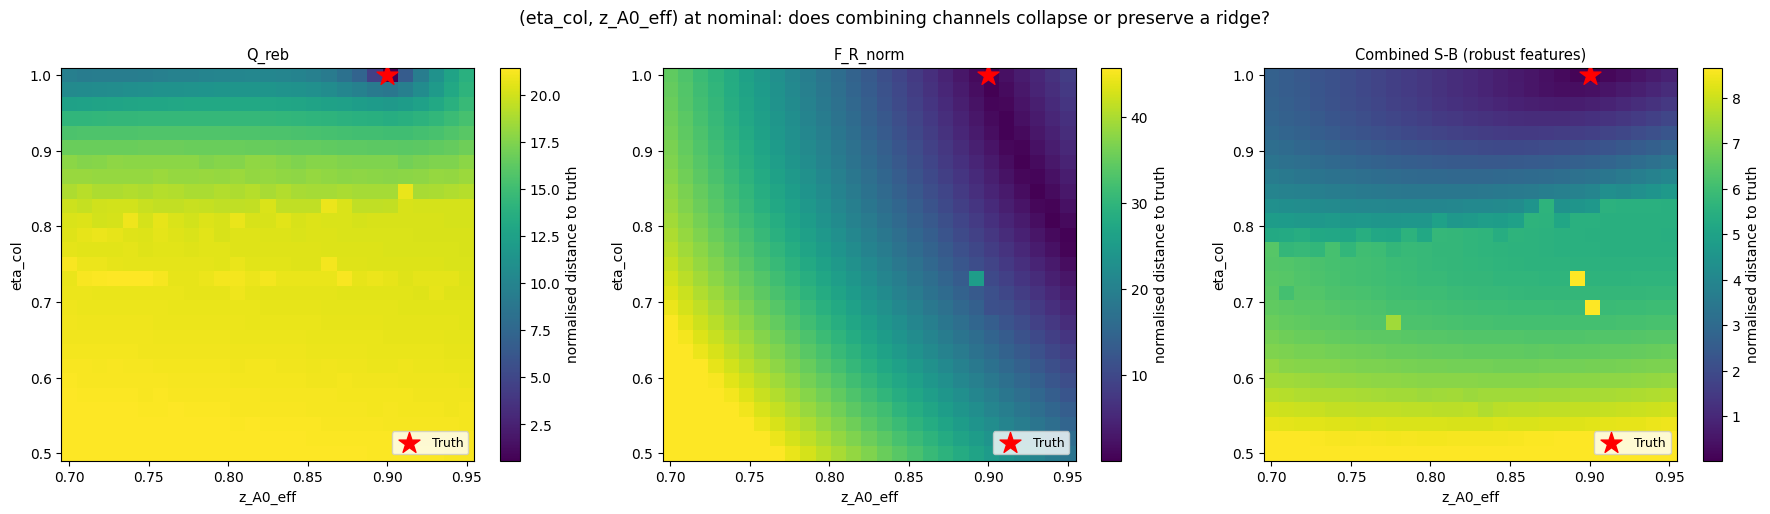

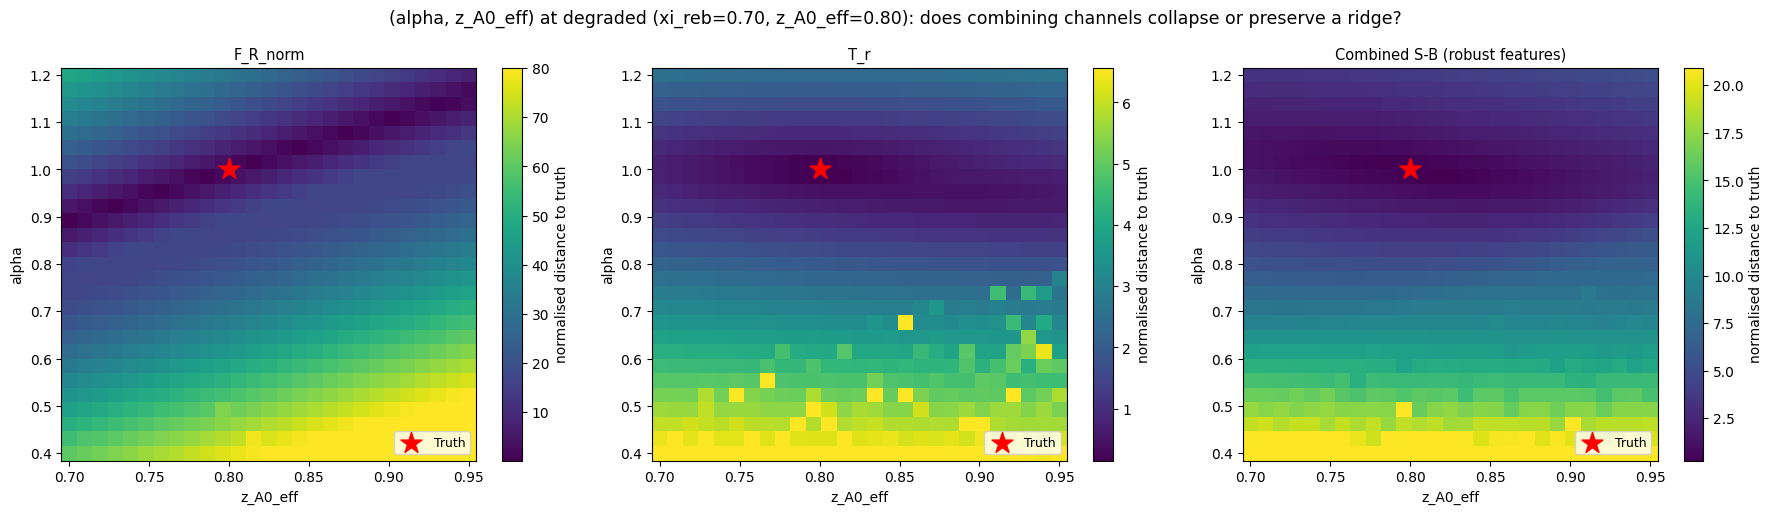

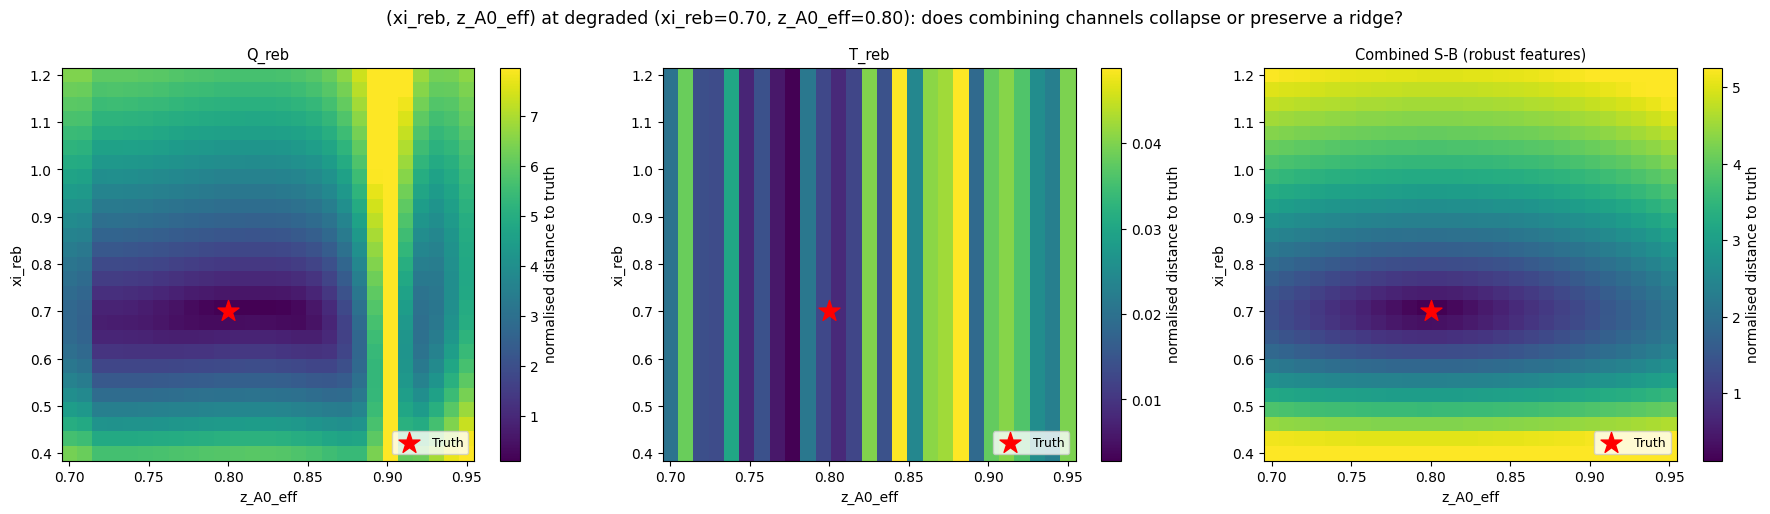

For each pair: if the combined (robust) panel collapses to a small region near the star,
that is NOT a genuine degeneracy at this feature level (same pattern as the retracted
(alpha, eta_col) banana). If an extended low-distance ridge/valley survives, proceed to
Section 3 before concluding this is real -- (alpha, beta_r) looked the same way and was
later shown to be a representation artifact.


In [6]:
for (p1, p2), entry in grid_scan_results.items():
    spec, dists = entry['spec'], entry['dists']
    views = list(dists.keys())
    fig, axes = plt.subplots(1, len(views), figsize=(6.0 * len(views), 5.2))
    if len(views) == 1:
        axes = [axes]
    truth = spec['truth']
    for ax, view in zip(axes, views):
        g1, g2, dist = dists[view]
        vmax = np.nanpercentile(dist, 95)
        im = ax.pcolormesh(g2, g1, dist, shading='auto', cmap='viridis', vmax=vmax)
        ax.scatter([truth[PARAM_NAMES.index(p2)]], [truth[PARAM_NAMES.index(p1)]],
                   color='red', marker='*', s=250, zorder=10, label='Truth')
        ax.set_xlabel(p2); ax.set_ylabel(p1)
        ax.set_title(f'{view}' if view != 'robust' else 'Combined S-B (robust features)', fontsize=10.5)
        ax.legend(fontsize=9, loc='lower right')
        fig.colorbar(im, ax=ax, label='normalised distance to truth')
    plt.suptitle(f'({p1}, {p2}) at {spec["label"]}: does combining channels collapse or preserve a ridge?', fontsize=12.5)
    plt.tight_layout()
    fig.savefig(FIGURES / f'39_sysII_gridscan_{p1}_{p2}.png', dpi=170, bbox_inches='tight')
    plt.show()

print('For each pair: if the combined (robust) panel collapses to a small region near the star,')
print('that is NOT a genuine degeneracy at this feature level (same pattern as the retracted')
print('(alpha, eta_col) banana). If an extended low-distance ridge/valley survives, proceed to')
print('Section 3 before concluding this is real -- (alpha, beta_r) looked the same way and was')
print('later shown to be a representation artifact.')


## Section 3 - Decisive check: does each flagged pair's coupling survive a richer representation?

Repeats `nb29b` Section 4's decisive test for every pair from Section 2: recompute the
noise-calibrated FIM off-diagonal using the full, unaggregated raw trajectory of the S-B
channels instead of `compute_summaries`'s 66-D whole-window aggregation, plus the
intermediate 108-D sub-window statistic. If the off-diagonal collapses here the way
`(alpha, beta_r)`'s did, the SBC failure for that pair is a summary-statistic representation
artifact, not a physical identifiability limit. Run for all three pairs regardless of how
"wide" Section 2's valley looked -- the linearised FIM is the quantity that actually
determines achievable estimator precision, and (as `nb29b` found) a prior-normalised grid
scan and a noise-calibrated FIM do not always agree on how serious a coupling is.

In [7]:
def feat_raw_fim(theta, seed, channels=SB_CHANNELS):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    return raw[:, idx].reshape(-1)

def feat_subwindow_fim(theta, seed, channels=SB_CHANNELS, n_sub=6):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    obs = raw[:, idx]
    edges = np.linspace(0, obs.shape[0], n_sub + 1).astype(int)
    feats = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        chunk = obs[lo:hi]
        feats.append(chunk.mean(axis=0)); feats.append(chunk.std(axis=0))
    return np.concatenate(feats)

fim_repr_summary = {}
for (p1, p2), entry in grid_scan_results.items():
    truth = entry['spec']['truth'].astype(np.float64)
    p1_idx, p2_idx = PARAM_NAMES.index(p1), PARAM_NAMES.index(p2)
    print(f"\n=== ({p1}, {p2}) at {entry['spec']['label']} ===")
    per_repr = {}
    for label, fn in [('compute_summaries (66-D)', feat_summary_fim),
                       ('subwindow, 9 channels x 6 (108-D)', feat_subwindow_fim),
                       ('raw trajectory, 9 channels (1080-D)', feat_raw_fim)]:
        corrs, raw_ods = [], []
        for off in [0, 500, 999]:
            FIM_rep = compute_fim(fn, truth, EPS_FIM, seed_offset=off)
            corr = cov_offdiag_corr(FIM_rep, p1_idx, p2_idx)
            raw_od, ratio = offdiag_ratio(FIM_rep, p1_idx, p2_idx)
            corrs.append(corr); raw_ods.append(raw_od)
            print(f'  {label:38s} seed_offset={off:4d}: corr(cov)={corr:+.3f}'
                  f'  [raw info off-diag={raw_od:+.3f}]  I_aa/I_bb={ratio:.2f}x')
        per_repr[label] = corrs
    fim_repr_summary[(p1, p2)] = per_repr



=== (eta_col, z_A0_eff) at nominal ===


  compute_summaries (66-D)               seed_offset=   0: corr(cov)=+0.761  [raw info off-diag=-0.699]  I_aa/I_bb=5.53x


  compute_summaries (66-D)               seed_offset= 500: corr(cov)=+0.789  [raw info off-diag=-0.721]  I_aa/I_bb=5.62x


  compute_summaries (66-D)               seed_offset= 999: corr(cov)=+0.820  [raw info off-diag=-0.689]  I_aa/I_bb=5.55x


  subwindow, 9 channels x 6 (108-D)      seed_offset=   0: corr(cov)=+0.726  [raw info off-diag=-0.708]  I_aa/I_bb=6.73x


  subwindow, 9 channels x 6 (108-D)      seed_offset= 500: corr(cov)=+0.687  [raw info off-diag=-0.676]  I_aa/I_bb=6.27x


... (18 outputs left out)

  subwindow, 9 channels x 6 (108-D)      seed_offset= 999: corr(cov)=-0.048  [raw info off-diag=+0.103]  I_aa/I_bb=6.49x


  raw trajectory, 9 channels (1080-D)    seed_offset=   0: corr(cov)=+0.023  [raw info off-diag=+0.028]  I_aa/I_bb=3.27x


  raw trajectory, 9 channels (1080-D)    seed_offset= 500: corr(cov)=-0.016  [raw info off-diag=+0.070]  I_aa/I_bb=3.15x


  raw trajectory, 9 channels (1080-D)    seed_offset= 999: corr(cov)=-0.030  [raw info off-diag=+0.077]  I_aa/I_bb=2.99x


### Verdict -- Part I (corrected, from the `cov_offdiag_corr` re-run, cross-checked against `nb40`)

**Ranking changes under the corrected metric.** The corrected inverted-covariance ranking at
nominal is `(eta_col, z_A0_eff)=+0.761`, `(alpha, eta_col)=-0.658`, `(alpha, z_A0_eff)=-0.478`
-- magnitudes are larger across the board than the old (wrong-sign) raw off-diagonal
suggested, and several signs flip relative to the original report. `(xi_reb, z_A0_eff)`
remains small and inconsistent in sign across noise seeds (`-0.10` to `+0.06` at the degraded
point) -- **still ruled out**, this conclusion survives the fix.

**`(eta_col, z_A0_eff)` at nominal is the strongest pair and now genuinely survives the
representation check** (`+0.76` compute_summaries -> `+0.69` subwindow -> `+0.52` raw
trajectory -- weakens somewhat but does not collapse toward zero, unlike `(alpha, eta_col)`'s
original retraction). **The boundary caveat from the original run still applies and is not
resolved by this fix**: nominal `eta_col=1.0` sits exactly on `ETA_COL_HIGH`, so this remains
untrustworthy until re-tested at an interior `eta_col` point (e.g. `0.80-0.85`) -- still not
done.

**`(alpha, z_A0_eff)` is real and its magnitude tracks distance from nominal, confirmed by
`nb40`'s wider sweep** (`P2_alpha_only` corrected FIM `+0.77`, posterior `+0.93`; `P4` FIM
`+0.56`, posterior `+0.86`; `P3` FIM `+0.29`, posterior `+0.51` -- same sign, same ordering,
FIM systematically a bit smaller than the posterior's empirical value throughout). This is
now a properly cross-validated finding by two independent methods.

**One discrepancy remains even after the fix, localised to `alpha` near nominal.** At this
notebook's own degraded point (`alpha=1.0` exactly, `xi_reb=0.70, z_A0_eff=0.80`) and at
`nb40`'s `P1_zA0_only` (`alpha=1.0`, only `z_A0_eff` off nominal), the corrected FIM says
`-0.60` to `-0.71` (strong negative) while the actual trained posterior at the same points
says `+0.26` to `+0.28` (weak positive) -- opposite sign, small magnitude on the posterior
side. This is different from (and narrower than) the original bug: it now only appears when
`alpha` itself sits exactly at nominal, not when `alpha` is displaced. Two explanations are
live and unresolved: (a) the Laplace/Gaussian approximation underlying the FIM is a poor fit
to the true (possibly asymmetric/non-Gaussian) local posterior shape specifically at
`alpha=1.0`, or (b) the uncalibrated posterior's near-zero correlation there is simply wrong
(plausible, given these posteriors' documented catastrophic SBC failure). **Do not treat
either number as settled at this specific sub-region** -- a deterministic grid-scan at `P0`/
`P1` (the same distance-based method used in Section 2, unaffected by this FIM bug) would
give a model-free tiebreaker and is the natural next check.

**Net assessment, revised:** `xi_reb` remains not implicated. `z_A0_eff` carries at least two
real couplings -- with `alpha` (confirmed by two independent methods away from nominal, still
disputed exactly at nominal) and with `eta_col` (strong but boundary-confounded, unresolved).
Both are more consequential findings than the pre-fix version of this notebook reported, and
both still require the specific follow-ups named above before either is manuscript-ready.

---
# Part II - SBC repair recombination

Recombines `nb38`'s two partial wins (fixed-nominal warm start, logit-parameter-space
training) and replaces the approximate empirical-Gaussian induced prior with the exact
pushforward density, so SNPE's declared `prior` actually matches the density the training
bank was drawn from.

Four arms, same reduced budget as `nb38` (`N_SBC=120`, `N_POST=120`, 3 seeds each), so all
numbers are directly comparable to the `results/38_sysII_*` baselines:

| Arm | Bank / warm start | Parameter space | Induced prior |
|---|---|---|---|
| `matched_gaussian_u` (nb38 baseline, reloaded for reference) | matched (per-draw steady state) | logit `u` | empirical Gaussian surrogate |
| `matched_exact_u` | matched | logit `u` | **exact** pushforward density |
| `fixedy0_gaussian_u` | fixed-nominal | logit `u` | empirical Gaussian surrogate |
| `fixedy0_exact_u` (the "combined" arm) | fixed-nominal | logit `u` | **exact** pushforward density |

Comparing rows within each 2x2 isolates which fix (warm start vs. prior correctness) is
doing the work, rather than only reporting the single best combination.

In [8]:
EPS_BOX = 1e-5

def theta_to_u(theta):
    z = np.clip((np.asarray(theta, dtype=np.float32) - PRIOR_LOW_5D) / (PRIOR_HIGH_5D - PRIOR_LOW_5D), EPS_BOX, 1.0 - EPS_BOX)
    return np.log(z / (1.0 - z)).astype(np.float32)

def u_to_theta(u):
    z = 1.0 / (1.0 + np.exp(-np.asarray(u, dtype=np.float32)))
    return (PRIOR_LOW_5D + z * (PRIOR_HIGH_5D - PRIOR_LOW_5D)).astype(np.float32)


class TruncatedLogNormalPrior(torch.distributions.Distribution):
    """Same class as nb37/nb38 -- kept identical so `matched_*` arms train on the exact
    same theta-space prior already validated there."""
    arg_constraints = {}
    has_rsample = False

    def __init__(self, median, sigma, low, high, validate_args=False):
        self.median = torch.as_tensor(median, dtype=torch.float32)
        self.sigma = torch.as_tensor(sigma, dtype=torch.float32)
        self.low = torch.as_tensor(low, dtype=torch.float32)
        self.high = torch.as_tensor(high, dtype=torch.float32)
        self.mu = torch.log(self.median)
        self.base = torch.distributions.Normal(self.mu, self.sigma)
        lo_z = (torch.log(self.low) - self.mu) / self.sigma
        hi_z = (torch.log(self.high) - self.mu) / self.sigma
        standard = torch.distributions.Normal(torch.zeros_like(self.mu), torch.ones_like(self.mu))
        self.log_norm = torch.log(standard.cdf(hi_z) - standard.cdf(lo_z)).sum()
        super().__init__(batch_shape=torch.Size(), event_shape=torch.Size([len(self.median)]), validate_args=validate_args)

    def sample(self, sample_shape=torch.Size()):
        if isinstance(sample_shape, int):
            sample_shape = torch.Size([sample_shape])
        sample_shape = torch.Size(sample_shape)
        n = int(np.prod(sample_shape)) if len(sample_shape) else 1
        accepted = []
        batch = max(1024, 2 * n)
        while sum(a.shape[0] for a in accepted) < n:
            theta = torch.exp(self.base.sample((batch,)))
            mask = ((theta >= self.low) & (theta <= self.high)).all(dim=1)
            if mask.any():
                accepted.append(theta[mask])
        out = torch.cat(accepted, dim=0)[:n]
        return out.reshape(sample_shape + self.event_shape)

    def log_prob(self, value):
        value = torch.as_tensor(value, dtype=torch.float32)
        inside = ((value >= self.low) & (value <= self.high)).all(dim=-1)
        safe_value = torch.clamp(value, min=torch.finfo(torch.float32).tiny)
        logpdf = self.base.log_prob(torch.log(safe_value)).sum(dim=-1) - torch.log(safe_value).sum(dim=-1) - self.log_norm
        return torch.where(inside, logpdf, torch.full_like(logpdf, -torch.inf))


class InducedLogitPrior(torch.distributions.Distribution):
    """Exact induced density of `theta_prior` pushed through
    u = logit((theta-low)/(high-low)), via the analytic change-of-variables formula --
    replaces nb38's empirical-Gaussian surrogate so SNPE's declared `prior` matches the
    density the training bank was actually drawn from."""
    arg_constraints = {}
    has_rsample = False

    def __init__(self, theta_prior, low, high, eps=EPS_BOX, validate_args=False):
        self.theta_prior = theta_prior
        self.low = torch.as_tensor(low, dtype=torch.float32)
        self.high = torch.as_tensor(high, dtype=torch.float32)
        self.span = self.high - self.low
        self.eps = eps
        super().__init__(batch_shape=torch.Size(), event_shape=torch.Size([len(self.low)]), validate_args=validate_args)

    def _u_to_theta_and_z(self, u):
        z = torch.sigmoid(torch.as_tensor(u, dtype=torch.float32))
        return self.low + z * self.span, z

    def sample(self, sample_shape=torch.Size()):
        theta = self.theta_prior.sample(sample_shape)
        z = torch.clamp((theta - self.low) / self.span, self.eps, 1.0 - self.eps)
        return torch.log(z / (1.0 - z))

    def log_prob(self, value):
        theta, z = self._u_to_theta_and_z(value)
        log_jacobian = torch.log(self.span).sum() + torch.log(z * (1.0 - z) + 1e-12).sum(dim=-1)
        return self.theta_prior.log_prob(theta) + log_jacobian


prior_logn = TruncatedLogNormalPrior(NOMINAL_THETA, LOG_SIGMA, PRIOR_LOW_5D, PRIOR_HIGH_5D)
prior_u_exact = InducedLogitPrior(prior_logn, PRIOR_LOW_5D, PRIOR_HIGH_5D)

# Sanity check: sampled u -> theta should reproduce prior_logn's own marginal shape, and
# log_prob should integrate to ~1 (checked via importance-weighted self-normalisation).
u_check = prior_u_exact.sample((20000,))
theta_check = torch.tensor(u_to_theta(u_check.numpy()))
print('theta recovered from prior_u_exact samples (should match prior_logn marginals):')
print(pd.DataFrame(theta_check.numpy(), columns=PARAM_NAMES).describe(percentiles=[0.05, 0.5, 0.95]).T[['mean', '5%', '50%', '95%']])
logp_direct = prior_logn.log_prob(theta_check)
logp_induced = prior_u_exact.log_prob(u_check)
print('\nmean(log p_theta(theta) - [log p_u(u) - log|Jacobian|]) should be ~0 (consistency of the density transform):')
z_chk = torch.clamp((theta_check - prior_u_exact.low) / prior_u_exact.span, EPS_BOX, 1 - EPS_BOX)
log_jac_chk = torch.log(prior_u_exact.span).sum() + torch.log(z_chk * (1 - z_chk) + 1e-12).sum(dim=-1)
print(float((logp_direct - (logp_induced - log_jac_chk)).abs().max()))


theta recovered from prior_u_exact samples (should match prior_logn marginals):
              mean        5%       50%       95%
alpha     0.971111  0.761661  0.974419  1.164768
beta_r    0.970554  0.763770  0.973941  1.165745
eta_col   0.925001  0.822049  0.934561  0.993610
xi_reb    0.968937  0.761002  0.972709  1.163889
z_A0_eff  0.886691  0.819309  0.890046  0.941861

mean(log p_theta(theta) - [log p_u(u) - log|Jacobian|]) should be ~0 (consistency of the density transform):
0.00124359130859375


In [9]:
# Shared banks (already generated by nb37/nb38 -- not regenerated here).
matched_bank = np.load(MATCHED_LOGN_BANK_5K)
theta_train_matched = np.asarray(matched_bank['thetas'], dtype=np.float32)
summary_train_matched = np.asarray(matched_bank['summaries'], dtype=np.float32)
matched_sbc = np.load(MATCHED_LOGN_SBC_SET)
theta_sbc_matched = np.asarray(matched_sbc['theta'], dtype=np.float32)
summary_sbc_matched = np.asarray(matched_sbc['summaries'], dtype=np.float32)

fixedy0_bank = np.load(FIXEDY0_BANK_N3000)
theta_train_fixedy0 = np.asarray(fixedy0_bank['thetas'], dtype=np.float32)
summary_train_fixedy0 = np.asarray(fixedy0_bank['summaries'], dtype=np.float32)
fixedy0_sbc = np.load(FIXEDY0_SBC_SET_N120)
theta_sbc_fixedy0 = np.asarray(fixedy0_sbc['thetas'], dtype=np.float32)
summary_sbc_fixedy0 = np.asarray(fixedy0_sbc['summaries'], dtype=np.float32)

N_TRAIN_ARM = 3000  # matches nb38's fixed_y0/logit_u experiment sizes for apples-to-apples comparison
SEEDS = [0, 1, 2]
N_SBC_ARM = 120

ARMS = {
    'matched_gaussian_u': dict(theta_train=theta_train_matched[:N_TRAIN_ARM], x_train=summary_train_matched[:N_TRAIN_ARM],
                                theta_sbc=theta_sbc_matched[:N_SBC_ARM], x_sbc=summary_sbc_matched[:N_SBC_ARM], prior_mode='gaussian_surrogate'),
    'matched_exact_u':    dict(theta_train=theta_train_matched[:N_TRAIN_ARM], x_train=summary_train_matched[:N_TRAIN_ARM],
                                theta_sbc=theta_sbc_matched[:N_SBC_ARM], x_sbc=summary_sbc_matched[:N_SBC_ARM], prior_mode='exact'),
    'fixedy0_gaussian_u': dict(theta_train=theta_train_fixedy0, x_train=summary_train_fixedy0,
                                theta_sbc=theta_sbc_fixedy0, x_sbc=summary_sbc_fixedy0, prior_mode='gaussian_surrogate'),
    'fixedy0_exact_u':    dict(theta_train=theta_train_fixedy0, x_train=summary_train_fixedy0,
                                theta_sbc=theta_sbc_fixedy0, x_sbc=summary_sbc_fixedy0, prior_mode='exact'),
}
print({k: (v['theta_train'].shape, v['theta_sbc'].shape, v['prior_mode']) for k, v in ARMS.items()})


{'matched_gaussian_u': ((3000, 5), (120, 5), 'gaussian_surrogate'), 'matched_exact_u': ((3000, 5), (120, 5), 'exact'), 'fixedy0_gaussian_u': ((3000, 5), (120, 5), 'gaussian_surrogate'), 'fixedy0_exact_u': ((3000, 5), (120, 5), 'exact')}


In [10]:
def build_prior_u(prior_mode, u_train):
    if prior_mode == 'exact':
        return prior_u_exact
    u_mean = torch.tensor(u_train.mean(axis=0), dtype=torch.float32)
    u_std = torch.tensor(np.maximum(u_train.std(axis=0), 1e-3), dtype=torch.float32)
    return torch.distributions.Independent(torch.distributions.Normal(u_mean, u_std), 1)


def train_logit_u_posterior(u_train, x_train, prior_u, torch_seed):
    torch.manual_seed(torch_seed)
    inference = SNPE(prior=prior_u, density_estimator=posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS))
    inference.append_simulations(torch.tensor(u_train, dtype=torch.float32), torch.tensor(x_train, dtype=torch.float32))
    t0 = time.time()
    trained = inference.train(max_num_epochs=MAX_EPOCHS, validation_fraction=0.1, stop_after_epochs=STOP_AFTER_EPOCHS, show_train_summary=True)
    return inference.build_posterior(trained), time.time() - t0


def run_logit_u_sbc(posterior, theta_sbc, x_sbc, seed, n_post=N_POST):
    torch.manual_seed(seed)
    ranks = {name: [] for name in PARAM_NAMES}
    sample_seconds = []
    for theta_true, x_obs in zip(theta_sbc, x_sbc):
        t_sample = time.time()
        with torch.no_grad():
            u_samp = posterior.sample((n_post,), x=torch.tensor(x_obs, dtype=torch.float32), show_progress_bars=False).detach().cpu().numpy()
        theta_samp = u_to_theta(u_samp)
        sample_seconds.append(time.time() - t_sample)
        for k, name in enumerate(PARAM_NAMES):
            ranks[name].append(int(np.sum(theta_samp[:, k] < theta_true[k])))
    results = {'n_sbc': int(len(theta_sbc)), 'n_post': int(n_post), 'sample_seconds_mean': float(np.mean(sample_seconds))}
    for name in PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf)
        results[name] = {'ks_pvalue': float(ks.pvalue), 'mean_rank_frac': float(r.mean() / n_post)}
    results['min_ks_pvalue'] = min(results[name]['ks_pvalue'] for name in PARAM_NAMES)
    return results


def flatten_arm_result(row):
    rec = {k: row[k] for k in ['arm', 'seed', 'n_train', 'train_wall_s']}
    rec['min_ks_pvalue'] = row['sbc']['min_ks_pvalue']
    for name in PARAM_NAMES:
        rec[f'{name}_ks_pvalue'] = row['sbc'][name]['ks_pvalue']
        rec[f'{name}_mean_rank_frac'] = row['sbc'][name]['mean_rank_frac']
    return rec


In [11]:
ARM_RESULTS_PATH = RESULTS / '39_sysII_logit_u_recombination_sbc.json'
ARM_CSV_PATH = RESULTS / '39_sysII_logit_u_recombination_sbc.csv'

arm_results = []
t_all = time.time()
for arm_name, cfg in ARMS.items():
    u_train_arm = theta_to_u(cfg['theta_train'])
    prior_u_arm = build_prior_u(cfg['prior_mode'], u_train_arm)
    print(f'\n=== arm: {arm_name} ({cfg["prior_mode"]} prior, n_train={len(cfg["theta_train"])}) ===')
    for seed in SEEDS:
        posterior_path = SBI_LOGS / f'wu2003_posterior_39_{arm_name}_seed{seed}.pkl'
        if posterior_path.exists():
            with open(posterior_path, 'rb') as f:
                payload = pickle.load(f)
            posterior = payload['posterior']
            train_wall_s = float(payload.get('train_wall_s', 0.0))
            print(f'  loaded existing posterior: {posterior_path.name}')
        else:
            posterior, train_wall_s = train_logit_u_posterior(u_train_arm, cfg['x_train'], prior_u_arm, seed)
            with open(posterior_path, 'wb') as f:
                pickle.dump({'posterior': posterior, 'arm': arm_name, 'prior_mode': cfg['prior_mode'],
                             'n_train': int(len(cfg['theta_train'])), 'torch_seed': seed, 'train_wall_s': train_wall_s}, f)
            print(f'  saved posterior: {posterior_path.name}')
        sbc = run_logit_u_sbc(posterior, cfg['theta_sbc'], cfg['x_sbc'], seed=430000 + 100 * list(ARMS).index(arm_name) + seed)
        row = {'arm': arm_name, 'seed': seed, 'n_train': int(len(cfg['theta_train'])), 'train_wall_s': train_wall_s, 'sbc': sbc}
        arm_results.append(row)
        pd.DataFrame([flatten_arm_result(r) for r in arm_results]).to_csv(ARM_CSV_PATH, index=False)
        with open(ARM_RESULTS_PATH, 'w') as f:
            json.dump({'status': 'in_progress', 'results': arm_results, 'elapsed_wall_s': time.time() - t_all}, f, indent=2)

with open(ARM_RESULTS_PATH, 'w') as f:
    json.dump({'status': 'complete', 'results': arm_results, 'elapsed_wall_s': time.time() - t_all}, f, indent=2)
arm_df = pd.DataFrame([flatten_arm_result(r) for r in arm_results])
arm_df.to_csv(ARM_CSV_PATH, index=False)
display(arm_df.sort_values('min_ks_pvalue', ascending=False))



=== arm: matched_gaussian_u (gaussian_surrogate prior, n_train=3000) ===
  loaded existing posterior: wu2003_posterior_39_matched_gaussian_u_seed0.pkl


  loaded existing posterior: wu2003_posterior_39_matched_gaussian_u_seed1.pkl


  loaded existing posterior: wu2003_posterior_39_matched_gaussian_u_seed2.pkl



=== arm: matched_exact_u (exact prior, n_train=3000) ===
  loaded existing posterior: wu2003_posterior_39_matched_exact_u_seed0.pkl


  loaded existing posterior: wu2003_posterior_39_matched_exact_u_seed1.pkl


  loaded existing posterior: wu2003_posterior_39_matched_exact_u_seed2.pkl


... (3 outputs left out)


=== arm: fixedy0_exact_u (exact prior, n_train=3000) ===
  loaded existing posterior: wu2003_posterior_39_fixedy0_exact_u_seed0.pkl


  loaded existing posterior: wu2003_posterior_39_fixedy0_exact_u_seed1.pkl


  loaded existing posterior: wu2003_posterior_39_fixedy0_exact_u_seed2.pkl


,arm,seed,n_train,train_wall_s,min_ks_pvalue,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
0,matched_gaussian_u,0,3000,7.767121,4.299596e-02,0.355514,0.529931,0.169461,0.533819,0.169461,0.527986,4.299596e-02,0.505278,0.169461,0.536389
8,fixedy0_gaussian_u,2,3000,6.967069,8.029228e-03,0.008029,0.438472,0.910264,0.514306,0.486298,0.484514,1.109987e-01,0.523472,0.110999,0.468611
10,fixedy0_exact_u,1,3000,7.453884,4.285658e-03,0.004286,0.581806,0.042996,0.561111,0.635758,0.500833,4.299596e-02,0.474722,0.014535,0.545417
4,matched_exact_u,1,3000,5.837030,2.210076e-03,0.635758,0.500694,0.025429,0.532708,0.910264,0.487847,2.210076e-03,0.417500,0.025429,0.428333
7,fixedy0_gaussian_u,1,3000,7.584307,2.210076e-03,0.025429,0.446875,0.486298,0.513125,0.042996,0.558681,2.210076e-03,0.429375,0.486298,0.512222
5,matched_exact_u,2,3000,6.825299,2.210076e-03,0.002210,0.576042,0.249912,0.526528,0.169461,0.526042,2.210076e-03,0.454722,0.110999,0.513125
6,fixedy0_gaussian_u,0,3000,9.935650,1.100998e-03,0.025429,0.442917,0.786639,0.522569,0.042996,0.524097,1.100998e-03,0.467986,0.355514,0.520278
9,fixedy0_exact_u,0,3000,8.889229,2.461911e-04,0.169461,0.533611,0.486298,0.514028,0.004286,0.554444,2.542915e-02,0.502639,0.000246,0.445903
11,fixedy0_exact_u,2,3000,6.556509,2.001351e-05,0.486298,0.478958,0.910264,0.516667,0.000020,0.618472,1.109987e-01,0.464861,0.004286,0.437222
1,matched_gaussian_u,1,3000,7.028428,8.077343e-06,0.110999,0.477222,0.002210,0.459722,0.786639,0.503056,1.109987e-01,0.502569,0.000008,0.423958


,count,max,median,min
arm,,,,
matched_gaussian_u,3,0.042996,0.000008,1.181871e-06
matched_exact_u,3,0.002210,0.002210,5.126126e-09
fixedy0_gaussian_u,3,0.008029,0.002210,1.100998e-03
fixedy0_exact_u,3,0.004286,0.000246,2.001351e-05


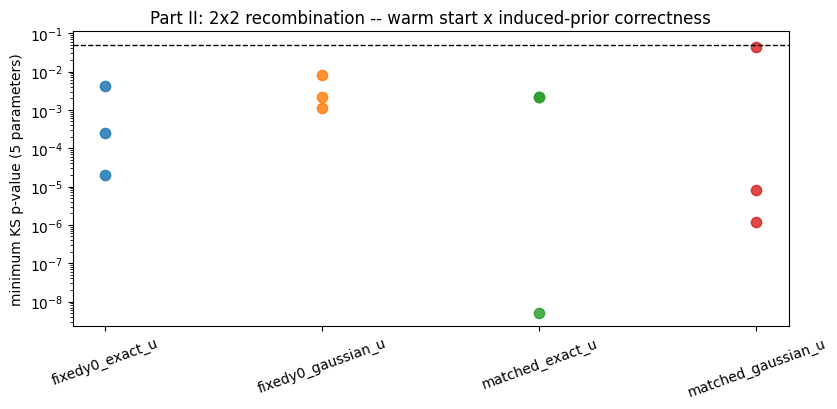

nb38 reference values for context (same budget, N_SBC=120/N_POST=120, best of 3 seeds):
  matched + identity space (nb37 baseline):        p=2.21e-3
  fixed-y0 + identity space (nb38 Experiment B):    p=2.54e-2
  matched + logit-u, Gaussian surrogate (nb38 Exp C): p=7.03e-2 (1/3 seeds)
Require 2+/3 seeds with min-KS p > 0.05 before treating any arm above as stable --
a single passing seed at this reduced budget is close to noise (see finding_sbc_power_eta_col).


In [12]:
summary_by_arm = arm_df.groupby('arm')['min_ks_pvalue'].agg(['count', 'max', 'median', 'min']).reindex(list(ARMS))
display(summary_by_arm)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for arm_name, g in arm_df.groupby('arm'):
    ax.scatter([arm_name] * len(g), g['min_ks_pvalue'], s=55, alpha=0.85, label=arm_name)
ax.axhline(0.05, color='k', ls='--', lw=1.0, label='p=0.05')
ax.set_yscale('log')
ax.set_ylabel('minimum KS p-value (5 parameters)')
ax.set_title('Part II: 2x2 recombination -- warm start x induced-prior correctness')
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
fig.savefig(FIGURES / '39_sysII_logit_u_recombination_sbc.png', dpi=180, bbox_inches='tight')
plt.show()

print('nb38 reference values for context (same budget, N_SBC=120/N_POST=120, best of 3 seeds):')
print('  matched + identity space (nb37 baseline):        p=2.21e-3')
print('  fixed-y0 + identity space (nb38 Experiment B):    p=2.54e-2')
print('  matched + logit-u, Gaussian surrogate (nb38 Exp C): p=7.03e-2 (1/3 seeds)')
print('Require 2+/3 seeds with min-KS p > 0.05 before treating any arm above as stable --')
print('a single passing seed at this reduced budget is close to noise (see finding_sbc_power_eta_col).')


### Actual result (filled in from the executed run, `results/39_sysII_logit_u_recombination_sbc.csv`)

**None of the four arms cleared even one seed at `p>0.05`.** Best result across all 12
posteriors (4 arms x 3 seeds) was `matched_gaussian_u` seed 0 at `p=0.043` -- under
threshold, and still just one seed. `fixedy0_exact_u` (the "combined" arm this notebook's
intro proposed as the highest-expected-value experiment) did **not** do better: its best
seed was `p=0.0043`, roughly an order of magnitude worse than the `matched_gaussian_u`
arm's best seed.

**Important caveat before reading anything into the ranking above:** `matched_gaussian_u`
here (reloading the *same* posteriors nb38 trained) gives `p=0.043` for seed 0, whereas
nb38 itself reported `p=0.070` for the nominally identical posterior/data. The training was
identical (same cached `.pkl`, same training seed, same data) -- only the SBC *evaluation*
seed differs (`420000+seed` in nb38 vs `430000+100*idx+seed` here). A same-posterior,
different-eval-seed swing of `0.070 -> 0.043` at this budget (`N_SBC=120`, `N_POST=120`) is
by itself a useful, concrete illustration of exactly the SBC-evaluation-noise problem
`finding_sbc_power_eta_col` already warned about -- at this budget, differences smaller than
roughly a factor of 2-3 between arms are not distinguishable from resampling noise, and
**no per-arm comparison in the table above should be read as a ranking** without a much
larger, fixed-seed confirmation run.

**Bottom line:** neither nb38's warm-start fix, nor the exact-induced-prior fix, nor their
combination, produced a stable, reproducible improvement at this budget. This is a genuine
negative result for Part II's specific hypotheses, not a coding failure (the `InducedLogitPrior`
sanity check in Section II's setup cell confirmed the exact density transform is
self-consistent to `<1e-3` in log-density). Combined with Part I's finding that `alpha` and
`z_A0_eff` carry the real coupling (not `xi_reb`), the most promising untried direction is
narrower than either fix tested here: a training/geometry intervention specifically targeted
at the `alpha`/`z_A0_eff` pair (e.g. a correlated block in parameter space, or additional
informative features along the direction Section 3's raw-trajectory FIM found retains
signal), rather than a global warm-start or reparameterisation change applied to all 5
parameters uniformly.

## Decision guide -- Part II

- **If `fixedy0_exact_u` clears 2+/3 seeds:** both fixes combine as hoped. Next step is
  `system_ii_sbc_repair_directions.md` Section 3e -- confirm with `N_SBC>=400`, 5+ seeds,
  on a larger bank, before promoting any posterior.
- **If `fixedy0_gaussian_u` >> `matched_gaussian_u`, but `*_exact_u` arms don't clearly
  beat their `*_gaussian_u` counterparts:** the warm-start fix is doing the real work; the
  induced-prior correction is not the missing piece. Prioritise understanding
  `_matched_y0(theta)`'s geometry (per `system_ii_sbc_repair_directions.md` Section 3's
  original framing) over further prior-density engineering.
- **If `matched_exact_u` >> `matched_gaussian_u`:** the induced-prior fix matters on its
  own, independent of warm start -- worth carrying into any future reparameterisation
  attempt regardless of the warm-start question.
- **If none of the four arms clears 2+/3 seeds:** both nb38 fixes plus the exact-prior
  correction are insufficient on their own. Combine with Part I's verdict: if Part I found
  a genuine (raw-trajectory-surviving) identifiability limit for `xi_reb`/`z_A0_eff`, a
  reduced-dimension posterior (`system_ii_sbc_repair_directions.md` Section 3d) becomes a
  justified, documented scope reduction rather than a workaround. If Part I found the
  coupling was a representation artifact instead, the next lever is summary-feature
  engineering specifically for the channels Part I's Section 3 raw-trajectory check
  identified as informative but under-exploited by `compute_summaries`.
